# FLDAS: observed monthly evapotranspiration anomalies, March–August 2020

NASA/JPL Mongolia dzud research reconstruction, based on **six original NASA Giovanni FLDAS NOAA monthly anomaly GeoTIFFs** found in the research archive. Source product: `FLDAS_NOAH01_C_GL_MA.001`, an anomaly **relative to the 1982–2016 month-specific climatology**. This is not the separate raw FLDAS model monthly average product. The source TIFFs explicitly tag the variable as `Anomaly of Total evapotranspiration`.

*Original research:* Aster Volta, NASA/JPL (2022). *Code reconstruction and scientific QA:* 2026.

In [1]:
from pathlib import Path
import sys
PROJECT=Path.cwd()
if not (PROJECT/'src').exists():PROJECT=PROJECT.parent
assert (PROJECT/'src').exists(), 'Launch Jupyter at repository root or notebooks/'
sys.path.insert(0,str(PROJECT))
from IPython.display import display,Image
import pandas as pd


## Verify source metadata and compute spatially weighted province statistics
All six source TIFFs contain georeferencing, actual anomaly values and flux units of `kg m⁻² s⁻¹`. Multiplication by 86,400 converts **anomaly flux** to the equivalent `mm/day`; both positive and negative values are scientifically meaningful.

In [2]:
from src.fldas import calculate_fldas, SECONDS_DAY
from src.pipeline import RESULTS
monthly=calculate_fldas()
print('Province-by-month real observations:',len(monthly))
display(monthly.groupby('month').et_anomaly_mm_per_day.agg(['min','mean','max']).reindex(['March','April','May','June','July','August']).round(3))
assert len(monthly)==132

Province-by-month real observations: 132


,min,mean,max
month,,,
March,-0.020,0.020,0.113
April,-0.079,-0.044,0.003
May,-0.214,-0.024,0.308
June,-0.078,0.428,1.116
July,-0.140,0.368,1.017
August,0.147,0.314,0.668


## Original-month geographic maps and 1982–2016 anomaly reference
These maps reproduce the **observed monthly anomaly product** with correctly matched dates, CRS, nodata treatment and units. They are not a standalone test of causality between ET anomalies, drought and animal deaths.

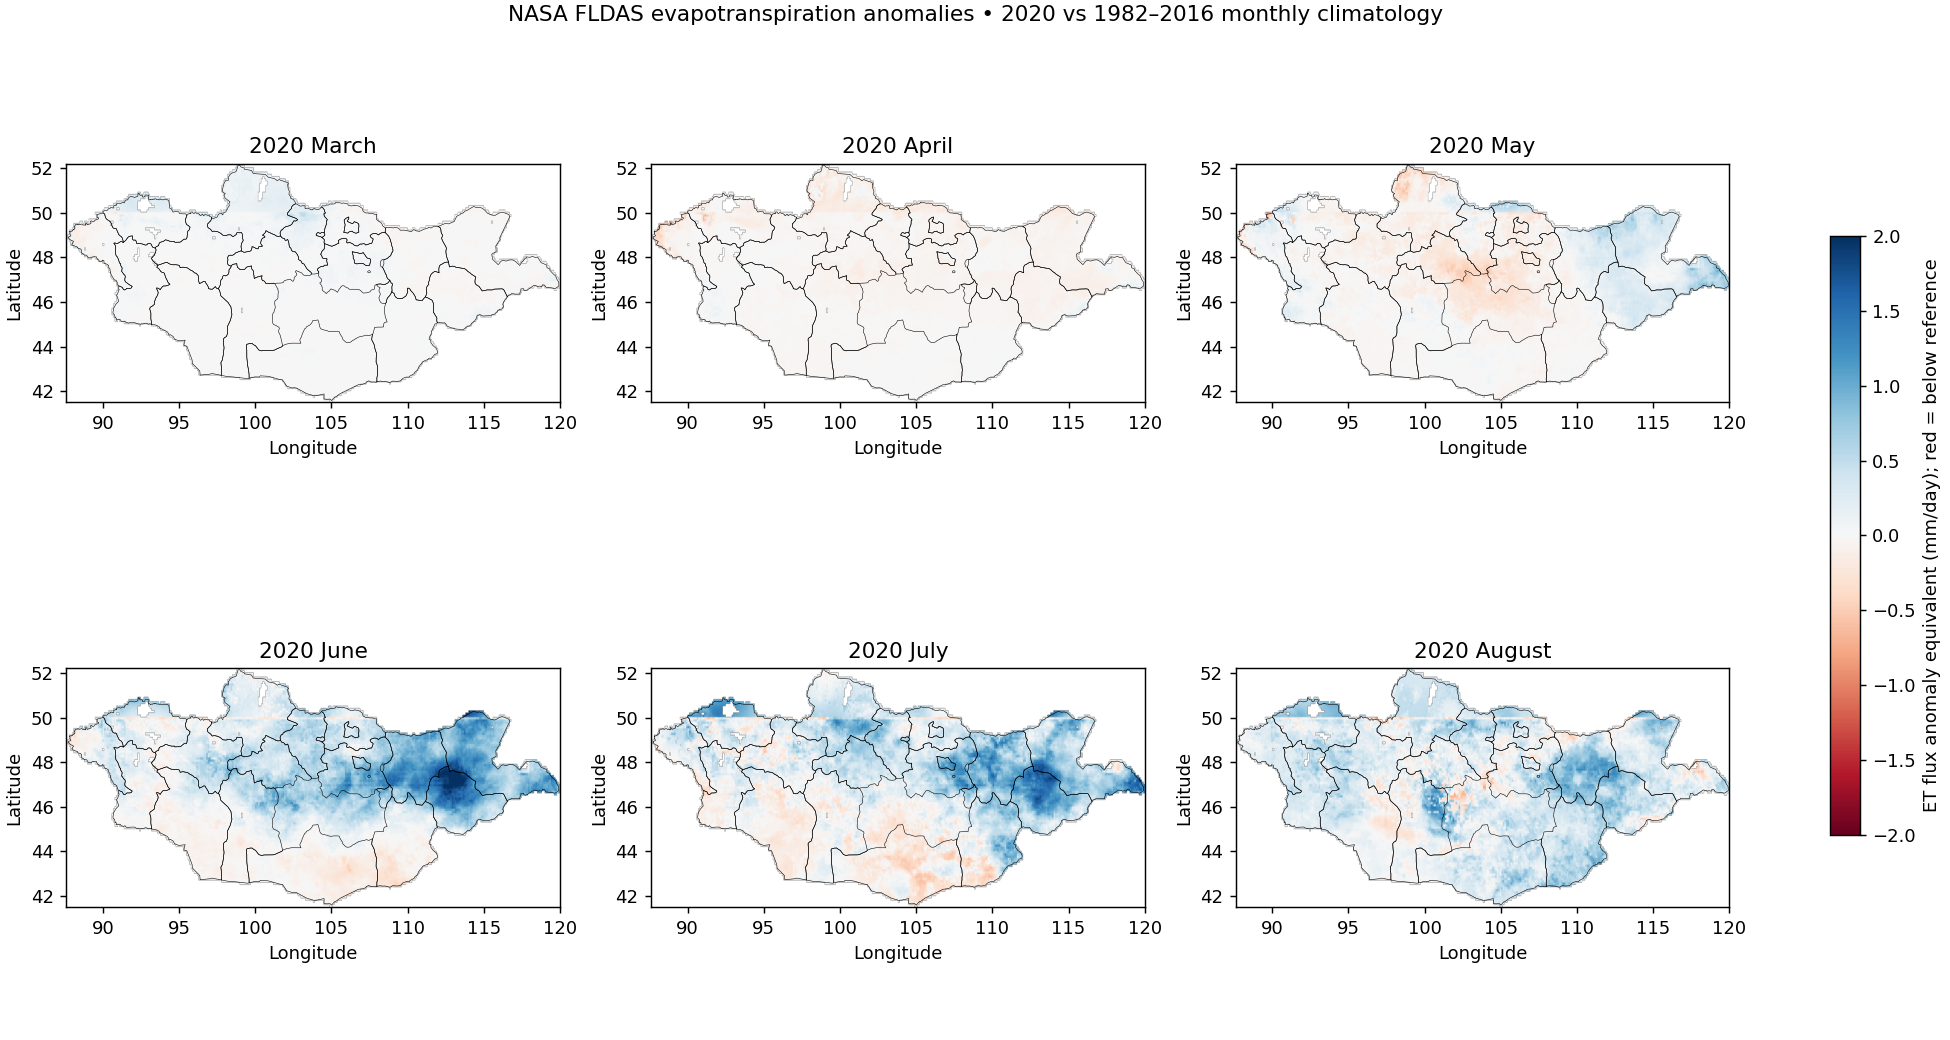

In [3]:
display(Image(filename=str(RESULTS/'08_fldas_et_anomalies_mar_aug_2020.png'),width=1150))

## Research notes
A positive ET anomaly means higher modeled ET flux relative to its month-specific climatology; it does **not** alone prove drought caused by ET. Physical interpretation requires precipitation, soil water supply and plant stress context. Product reference: NASA `FLDAS_NOAH01_C_GL_MA` (1982–2016 climatology). Units and source provenance are retained in the GeoTIFF metadata and repository data catalog.